In [157]:
import pandas as pd

# Data Loading

In [158]:
df_news = pd.read_csv("DJIA_news_data.csv")
df_stock = pd.read_csv("DJIA_stock_data.csv")

print(df_news.shape)  # (1989, 28)
print(df_stock.shape)  # (1989, 5)   

(1989, 27)
(1989, 6)


# Data Preparation

In [159]:
# Combine news columns into a single 'News' column
df_news['News'] = df_news.iloc[:, 2:].apply(lambda x: ' '.join(x.dropna().astype(str)), axis=1)

# Merge news and stock data on 'Date'
df = pd.merge(df_stock, df_news[['Date', 'News', 'Label']], on='Date')

# Saving the combined dataset
# df.to_csv("DJIA_data.csv", index=False)

In [160]:
df = pd.read_csv("DJIA_data.csv")
df['Label'] = (df['Close'].diff().shift(-1) >= 0).astype(int)
df.head()

,Date,Close,High,Low,Open,Volume,News,Label
0,2008-08-08,11734.320312,11759.959961,11388.040039,11432.089844,212830000,"b""Georgia 'downs two Russian warplanes' as cou...",1
1,2008-08-11,11782.349609,11867.110352,11675.530273,11729.669922,183190000,b'Why wont America and Nato help us? If they w...,0
2,2008-08-12,11642.469727,11782.349609,11601.519531,11781.700195,173590000,b'Remember that adorable 9-year-old who sang a...,0
3,2008-08-13,11532.959961,11633.780273,11453.339844,11632.809570,182550000,b' U.S. refuses Israel weapons to attack Iran:...,1
4,2008-08-14,11615.929688,11718.280273,11450.889648,11532.070312,159790000,b'All the experts admit that we should legalis...,1


# Text Preprocessing

In [161]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.stem import PorterStemmer
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/nouroudine/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Text Cleaning

In [162]:
def clean_text(text):
    text = str(text)
    
    # Strip all b' and b" markers anywhere in the string
    text = re.sub(r'\bb[\'"]', ' ', text)
    
    # Lowercase
    text = text.lower()
    
    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)
    
    # Collapse whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    # Remove stopwords
    stop_words = set(stopwords.words('english'))
    words = [w for w in text.split() if w not in stop_words]
    
    return ' '.join(words)

In [163]:
# Apply the cleaning function to the 'News' column
df['Cleaned_News'] = df['News'].apply(clean_text)

## Text Stemming

In [164]:
def text_stemming(text):
	ps = PorterStemmer()
	return ' '.join([ps.stem(word) for word in text.split()])

In [167]:
# Apply the cleaning function to the 'News' column
df['Cleaned_News'] = df['Cleaned_News'].apply(text_stemming)

In [142]:
df.head()

,Date,Close,High,Low,Open,Volume,News,Label,Cleaned_News
0,2008-08-08,11734.320312,11759.959961,11388.040039,11432.089844,212830000,"b""Georgia 'downs two Russian warplanes' as cou...",1,georgia downs two russian warplanes countries ...
1,2008-08-11,11782.349609,11867.110352,11675.530273,11729.669922,183190000,b'Why wont America and Nato help us? If they w...,0,wont america nato help us wont help us help ir...
2,2008-08-12,11642.469727,11782.349609,11601.519531,11781.700195,173590000,b'Remember that adorable 9-year-old who sang a...,0,remember adorable yearold sang opening ceremon...
3,2008-08-13,11532.959961,11633.780273,11453.339844,11632.809570,182550000,b' U.S. refuses Israel weapons to attack Iran:...,1,us refuses israel weapons attack iran report p...
4,2008-08-14,11615.929688,11718.280273,11450.889648,11532.070312,159790000,b'All the experts admit that we should legalis...,1,experts admit legalise drugs war south osetia ...


Train: 1611 jours (2008-08-08 → 2014-12-31)
Test:  378 jours (2015-01-02 → 2016-07-01)
Label balance train: {1: 875, 0: 736}
Label balance test:  {1: 192, 0: 186}


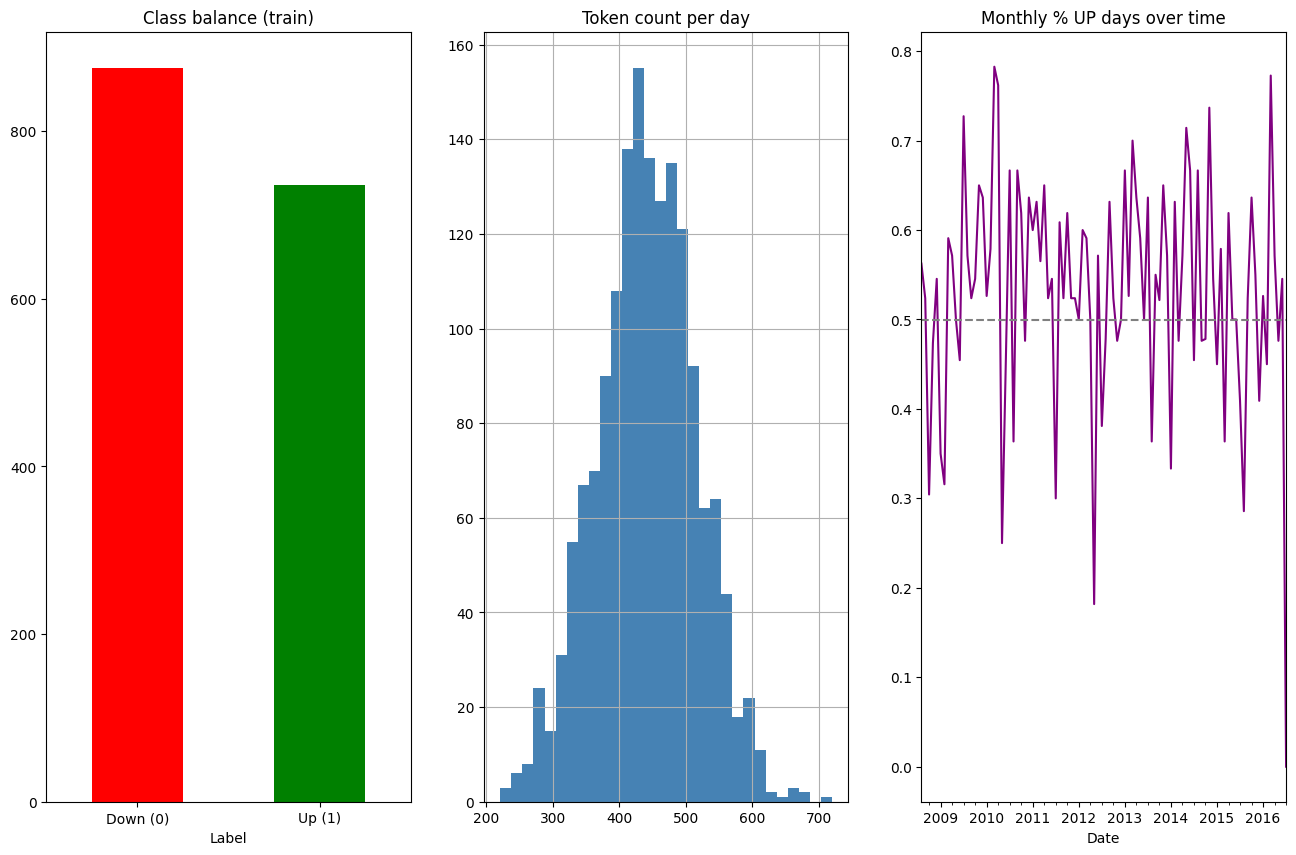

In [168]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 10))
train = df[df['Date'] < '2015-01-01'].reset_index(drop=True)
test  = df[df['Date'] >= '2015-01-01'].reset_index(drop=True)

print(f"Train: {len(train)} jours ({train['Date'].min()} → {train['Date'].max()})")
print(f"Test:  {len(test)} jours ({test['Date'].min()} → {test['Date'].max()})")
print(f"Label balance train: {train['Label'].value_counts().to_dict()}")
print(f"Label balance test:  {test['Label'].value_counts().to_dict()}")
# 1. Class balance
train['Label'].value_counts().plot(kind='bar', ax=axes[0], color=['red','green'])
axes[0].set_title('Class balance (train)')
axes[0].set_xticklabels(['Down (0)', 'Up (1)'], rotation=0)

# 2. Token count per day
train['text_len'] = train['News'].apply(lambda x: len(x.split()))
train['text_len'].hist(bins=30, ax=axes[1], color='steelblue')
axes[1].set_title('Token count per day')

# 3. Label over time
df['Date'] = pd.to_datetime(df['Date'])
monthly = df.set_index('Date')['Label'].resample('ME').mean()
monthly.plot(ax=axes[2], color='purple')
axes[2].set_title('Monthly % UP days over time')
axes[2].axhline(0.5, linestyle='--', color='gray')

In [170]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt


def generate_word_cloud(text):
    
    # Add custom stop words
    custom_stopwords = {"israel", "israeli", "say", "call", "report", "news", "say", "says", "said", "according", "according to", "report", "reports", "reported", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"}
    # Update the default stop words included in the WordCloud library with our custom stop words
    stopwords = set(STOPWORDS)
    stopwords.update(custom_stopwords)

    # Generate the WordCloud object
    wordcloud = WordCloud(width = 1600, height = 800, stopwords = stopwords, min_font_size = 10).generate(text)

    # Display the WordCloud 
    plt.figure(figsize = (12, 12))
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

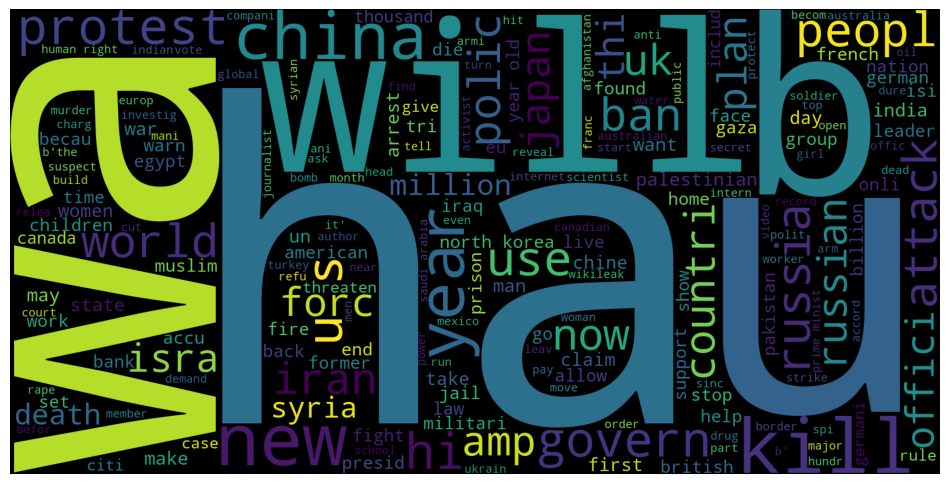

In [171]:
# Generate word cloud visualization for text with positive sentiment
generate_word_cloud(" ".join(df[df['Label'] == 1]['Cleaned_News']))

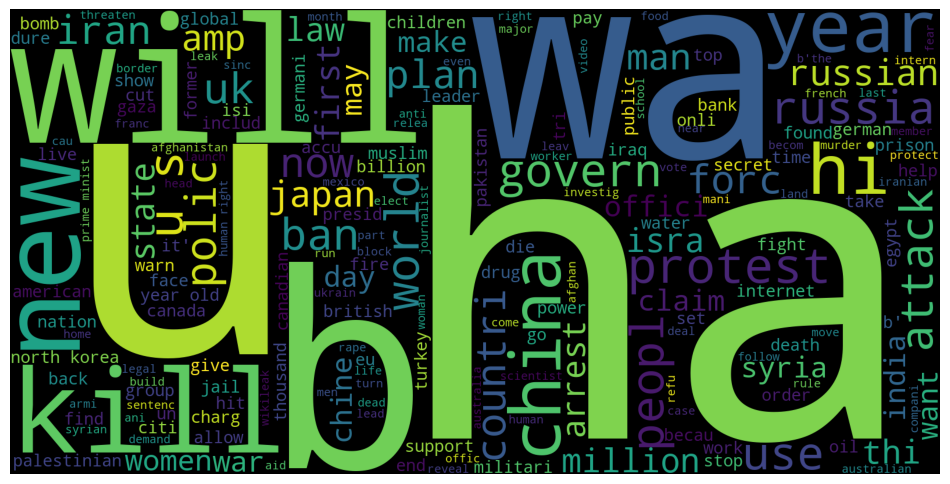

In [172]:
# Generate word cloud visualization for text with negative sentiment
generate_word_cloud(" ".join(df[df['Label'] == 0]['Cleaned_News']))

# Text Feature engineering

In [148]:
import pandas as pd
import numpy as np
from textblob import TextBlob
import re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [149]:
# create function to get the sentiment score:

def getSIA(text):
    sia = SentimentIntensityAnalyzer()
    sentiment= sia.polarity_scores(text)
    return sentiment

# get Sentiment score for each day:
compound=[]
neg=[]
pos=[]
neu=[]
SIA=0

for i in range (0, len(df['News'])):
    SIA= getSIA(df['News'][i])
    compound.append(SIA['compound'])
    neg.append(SIA['neg'])
    pos.append(SIA['pos'])
    neu.append(SIA['neu'])
    
df['compound']= compound
df['neg']= neg
df['pos']=pos
df['neu']=neu

In [150]:
df.head()

,Date,Close,High,Low,Open,Volume,News,Label,Cleaned_News,compound,neg,pos,neu
0,2008-08-08,11734.320312,11759.959961,11388.040039,11432.089844,212830000,"b""Georgia 'downs two Russian warplanes' as cou...",1,georgia downs two russian warplanes countries ...,-0.9979,0.229,0.049,0.723
1,2008-08-11,11782.349609,11867.110352,11675.530273,11729.669922,183190000,b'Why wont America and Nato help us? If they w...,0,wont america nato help us wont help us help ir...,-0.9804,0.170,0.081,0.749
2,2008-08-12,11642.469727,11782.349609,11601.519531,11781.700195,173590000,b'Remember that adorable 9-year-old who sang a...,0,remember adorable yearold sang opening ceremon...,-0.9658,0.122,0.056,0.823
3,2008-08-13,11532.959961,11633.780273,11453.339844,11632.809570,182550000,b' U.S. refuses Israel weapons to attack Iran:...,1,us refuses israel weapons attack iran report p...,-0.9809,0.145,0.065,0.790
4,2008-08-14,11615.929688,11718.280273,11450.889648,11532.070312,159790000,b'All the experts admit that we should legalis...,1,experts admit legalise drugs war south osetia ...,-0.9802,0.167,0.095,0.738


In [151]:
#create the feature data set:
X=df.drop(['Label', 'Date', 'News', 'Cleaned_News'], axis=1)

X=np.array(X)

#create the target data set:

y= np.array(df['Label'])

# Split the data:

x_train, x_test, y_train, y_test= train_test_split(X,y, test_size=0.2, shuffle=False)

#create and train the model:

model= LinearDiscriminantAnalysis().fit(x_train, y_train)

# Model predicton:

predict= model.predict(x_test)

predict

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0,

In [152]:
print(classification_report(y_test, predict))

              precision    recall  f1-score   support

           0       0.49      0.22      0.30       196
           1       0.51      0.78      0.61       202

    accuracy                           0.50       398
   macro avg       0.50      0.50      0.46       398
weighted avg       0.50      0.50      0.46       398



In [174]:
import numpy as np
import tensorflow as tf 
from tensorflow import keras
from tensorflow import keras
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [182]:
max_length = 50
import json

with open("Sarcasm_fixed.json", 'r') as f:
    data = json.load(f)
headlines = []
is_sarcastic = []
for item in data:
    headlines.append(item['headline'])
    is_sarcastic.append(item['is_sarcastic'])

training_sentences = headlines[:20000]
test_sentences = headlines[20000:]
training_labels = is_sarcastic[:20000]
test_labels = is_sarcastic[20000:]


tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(training_sentences)

sequences = tokenizer.texts_to_sequences(training_sentences)
padded = np.array(pad_sequences(sequences, padding="post", maxlen=max_length), dtype=np.float32)

test_seq = tokenizer.texts_to_sequences(test_sentences)
test_pad = np.array(pad_sequences(test_seq, padding="post", maxlen=max_length), dtype=np.float32)

In [187]:
import numpy as np
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. Charger GloVe
embeddings_index = {}
with open('glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        embeddings_index[values[0]] = np.array(values[1:], dtype='float32')

# 2. Construire la matrice d'embeddings
vocab_size = len(tokenizer.word_index) + 1
embedding_matrix = np.zeros((vocab_size, 100))
for word, i in tokenizer.word_index.items():
    vec = embeddings_index.get(word)
    if vec is not None:
        embedding_matrix[i] = vec

# 3. Modèle avec régularisation
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=100,
              weights=[embedding_matrix], trainable=False),
    Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.3)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 4. EarlyStopping
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    padded, training_labels,
    epochs=30,
    validation_data=(test_pad, test_labels),
    callbacks=[es],
    batch_size=32
)

ValueError: Unrecognized data type: x=[[3.2800e+02 1.2776e+04 7.9900e+02 ... 0.0000e+00 0.0000e+00 0.0000e+00]
 [4.0000e+00 6.8400e+03 3.0960e+03 ... 0.0000e+00 0.0000e+00 0.0000e+00]
 [1.5300e+02 8.9000e+02 2.0000e+00 ... 0.0000e+00 0.0000e+00 0.0000e+00]
 ...
 [7.9000e+01 1.7290e+03 2.5635e+04 ... 0.0000e+00 0.0000e+00 0.0000e+00]
 [5.3000e+01 5.1080e+03 4.7350e+03 ... 0.0000e+00 0.0000e+00 0.0000e+00]
 [3.1200e+02 7.0500e+02 1.1705e+04 ... 0.0000e+00 0.0000e+00 0.0000e+00]] (of type <class 'numpy.ndarray'>)